# Classifier evaluation: repeated CV, per-class metrics, confusion matrices, latency protocol

In [1]:
import os, sys, time, json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from scipy import stats
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_validate, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)

# >>> Adjust path, features and target if needed
FILE_PATH = "pon_synthetic_dataset_50000_overlap.csv"
features = ["packet_size_bytes", "packets_per_sec", "traffic_rate_mbps"]
target = "traffic_type"
SEED = 42

data = pd.read_csv(FILE_PATH)
X, y = data[features], data[target]
classes = sorted(y.unique())
print(X.shape, classes)

# >>> IMPORTANT: copy here the SAME hyperparameters you used in the original notebook.
# KNN and SVM use standardization (inside the pipeline, so it is fit only on training folds);
# Random Forest is trained without scaling, as in Table 7 of the paper.
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=1),
    "SVM": make_pipeline(StandardScaler(), SVC(random_state=SEED)),
}

(50000, 3) ['gaming', 'iot', 'video', 'web']


## A. Environment

In [2]:
# ---------------------------------------------------------
# A. COMPUTING ENVIRONMENT (to report in the paper)
# ---------------------------------------------------------
try:
    import psutil
    ram_gb = round(psutil.virtual_memory().total / 1e9, 1)
except ImportError:
    ram_gb = "n/a (pip install psutil)"

env = {
    "OS": platform.platform(),
    "CPU": platform.processor() or platform.machine(),
    "Logical cores": os.cpu_count(),
    "RAM (GB)": ram_gb,
    "GPU used": "No (CPU only)",
    "Python": sys.version.split()[0],
    "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
}
for k, v in env.items(): print(f"{k:14s}: {v}")
json.dump(env, open("results/environment.json", "w"), indent=2)

OS            : Windows-11-10.0.26200-SP0
CPU           : Intel64 Family 6 Model 94 Stepping 3, GenuineIntel
Logical cores : 8
RAM (GB)      : 12.8
GPU used      : No (CPU only)
Python        : 3.14.6
numpy         : 2.4.6
pandas        : 3.0.3
scipy         : 1.18.0
scikit-learn  : 1.9.0


## B. Repeated cross-validation

KNN            done
Random Forest  done
SVM            done


,Model,Test F1 (mean),Test F1 (std),95% CI low,95% CI high,Train-test gap (mean),Train-test gap (std),Fit time per fold (s)
0,KNN,0.7933,0.0031,0.7924,0.7942,0.0560,0.0036,0.1059
1,Random Forest,0.8039,0.0027,0.8031,0.8047,0.1961,0.0027,4.3761
2,SVM,0.8161,0.0026,0.8153,0.8168,0.0006,0.0034,22.1106


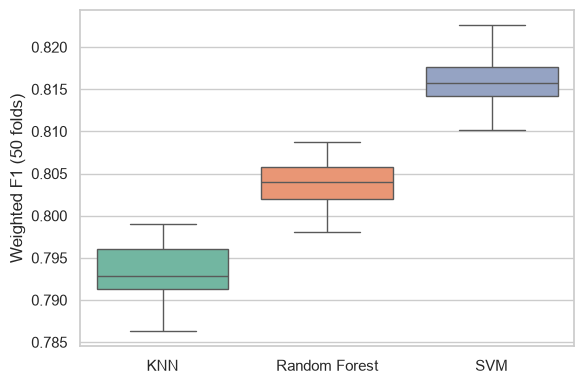

In [3]:
# ---------------------------------------------------------
# B. REPEATED STRATIFIED 5-FOLD CROSS-VALIDATION (10 repeats = 50 folds)
# Same splits for every model (same seed) -> paired comparison is valid.
# ---------------------------------------------------------
N_SPLITS, N_REPEATS = 5, 10
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

fold_scores = {}
for name, model in models.items():
    res = cross_validate(model, X, y, cv=cv, scoring="f1_weighted",
                         return_train_score=True, n_jobs=1)
    fold_scores[name] = res
    print(f"{name:14s} done")

rows = []
for name, r in fold_scores.items():
    te, tr = r["test_score"], r["train_score"]
    ci = stats.t.interval(0.95, len(te) - 1, loc=te.mean(), scale=stats.sem(te))
    rows.append({"Model": name,
                 "Test F1 (mean)": te.mean(), "Test F1 (std)": te.std(ddof=1),
                 "95% CI low": ci[0], "95% CI high": ci[1],
                 "Train-test gap (mean)": (tr - te).mean(),
                 "Train-test gap (std)": (tr - te).std(ddof=1),
                 "Fit time per fold (s)": r["fit_time"].mean()})
cv_table = pd.DataFrame(rows).round(4)
cv_table.to_csv("results/cv_summary.csv", index=False)
display(cv_table)

# Boxplot of the 50 fold scores
plt.figure(figsize=(6, 4))
sns.boxplot(data=pd.DataFrame({k: v["test_score"] for k, v in fold_scores.items()}))
plt.ylabel("Weighted F1 (50 folds)"); plt.tight_layout()
plt.savefig("figures/cv_f1_boxplot.png", dpi=300, bbox_inches="tight"); plt.show()

## C. Statistical comparison

In [4]:
# ---------------------------------------------------------
# C. STATISTICAL COMPARISON BETWEEN MODELS
# Nadeau-Bengio corrected resampled t-test (accounts for overlapping training sets)
# + Wilcoxon signed-rank on the paired fold scores. Holm correction over 3 comparisons.
# ---------------------------------------------------------
k = N_SPLITS * N_REPEATS
test_over_train = 1 / (N_SPLITS - 1)          # n_test / n_train

def corrected_ttest(a, b):
    d = np.asarray(a) - np.asarray(b)
    if np.allclose(d.var(ddof=1), 0): return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / k + test_over_train) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), k - 1)

names = list(models)
pairs = [(names[i], names[j]) for i in range(len(names)) for j in range(i + 1, len(names))]
out = []
for a, b in pairs:
    sa, sb = fold_scores[a]["test_score"], fold_scores[b]["test_score"]
    t, p_t = corrected_ttest(sa, sb)
    try: p_w = stats.wilcoxon(sa, sb).pvalue
    except ValueError: p_w = 1.0
    out.append({"A": a, "B": b, "mean diff (A-B)": (sa - sb).mean(),
                "corrected t": t, "p (corrected t)": p_t, "p (Wilcoxon)": p_w})
cmp_df = pd.DataFrame(out)
# Holm-Bonferroni adjustment of the corrected-t p-values
order = cmp_df["p (corrected t)"].rank(method="first").astype(int).values
m = len(cmp_df)
holm = np.minimum(1, cmp_df["p (corrected t)"].values * (m - order + 1))
cmp_df["p Holm (corrected t)"] = np.maximum.accumulate(holm[np.argsort(order)])[np.argsort(np.argsort(order))]
cmp_df = cmp_df.round(4)
cmp_df.to_csv("results/pairwise_comparison.csv", index=False)
display(cmp_df)

# Friedman test (global): do the three models differ at all?
chi2, p_f = stats.friedmanchisquare(*[fold_scores[n]["test_score"] for n in names])
print(f"Friedman test: chi2 = {chi2:.3f}, p = {p_f:.4g}")

,A,B,mean diff (A-B),corrected t,p (corrected t),p (Wilcoxon),p Holm (corrected t)
0,KNN,Random Forest,-0.0106,-7.5740,0.0,0.0,0.0
1,KNN,SVM,-0.0228,-14.0287,0.0,0.0,0.0
2,Random Forest,SVM,-0.0122,-9.6246,0.0,0.0,0.0


Friedman test: chi2 = 100.000, p = 1.929e-22


## D. Confusion matrices and per-class metrics

F1 by class,KNN,Random Forest,SVM
Class,,,
gaming,0.574,0.580,0.594
iot,0.978,0.978,0.980
video,0.868,0.874,0.885
web,0.726,0.744,0.768


,Model,Class,Precision,Recall,F1,Support
0,KNN,gaming,0.5729,0.5761,0.5745,9049.0
1,KNN,iot,0.9696,0.9855,0.9775,9913.0
2,KNN,video,0.8660,0.8695,0.8678,16118.0
3,KNN,web,0.7324,0.7188,0.7256,14920.0
4,Random Forest,gaming,0.6062,0.5551,0.5795,9049.0
5,Random Forest,iot,0.9743,0.9825,0.9784,9913.0
6,Random Forest,video,0.8723,0.8767,0.8745,16118.0
7,Random Forest,web,0.7298,0.7591,0.7442,14920.0
8,SVM,gaming,0.6588,0.5402,0.5936,9049.0
9,SVM,iot,0.9727,0.9877,0.9801,9913.0


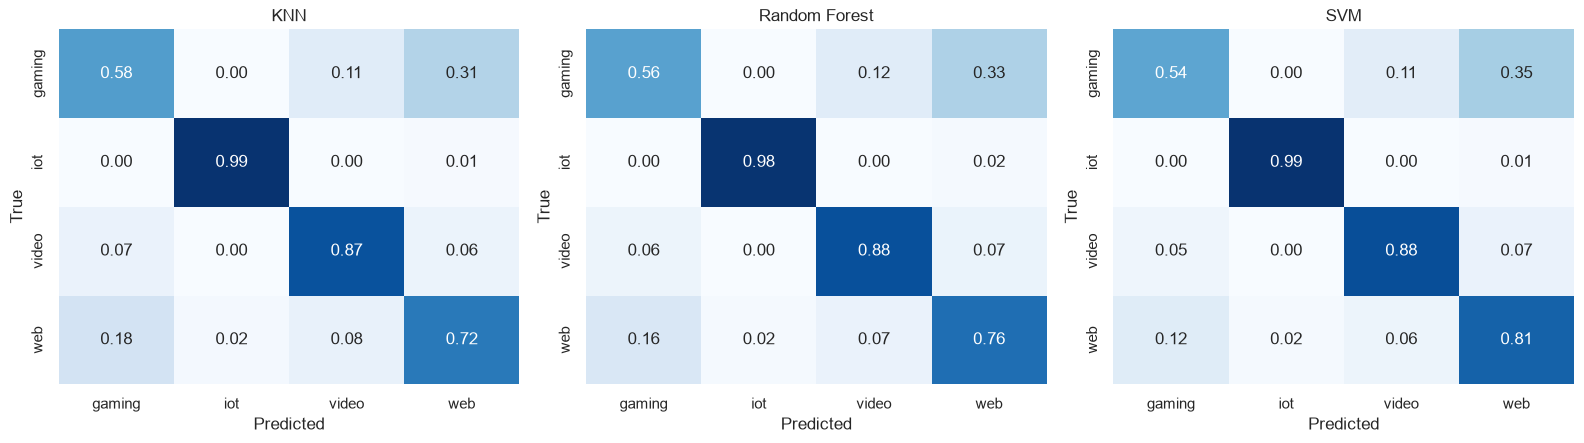

KNN            web->gaming: 18.5% | gaming->web: 30.9%
Random Forest  web->gaming: 15.6% | gaming->web: 32.8%
SVM            web->gaming: 11.8% | gaming->web: 35.1%


In [5]:
# ---------------------------------------------------------
# D. CONFUSION MATRICES AND PER-CLASS METRICS
# D1: pooled out-of-fold predictions (every sample predicted once, never seen in training)
# D2: the original 70/30 hold-out split (random_state=42), for continuity with the paper
# ---------------------------------------------------------
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)

per_class, confusions = [], {}
for name, model in models.items():
    y_oof = cross_val_predict(model, X, y, cv=skf, n_jobs=1)
    rep = classification_report(y, y_oof, labels=classes, output_dict=True, zero_division=0)
    for c in classes:
        per_class.append({"Model": name, "Class": c, "Precision": rep[c]["precision"],
                          "Recall": rep[c]["recall"], "F1": rep[c]["f1-score"],
                          "Support": rep[c]["support"]})
    confusions[name] = confusion_matrix(y, y_oof, labels=classes)

    # hold-out report for continuity
    y_hat = model.fit(X_tr, y_tr).predict(X_te)
    pd.DataFrame(classification_report(y_te, y_hat, labels=classes, output_dict=True)
                 ).T.round(4).to_csv(f"results/per_class_holdout_{name.replace(' ', '_')}.csv")

pc = pd.DataFrame(per_class).round(4)
pc.to_csv("results/per_class_metrics_cv.csv", index=False)
display(pc.pivot(index="Class", columns="Model", values="F1").round(3).rename_axis(columns="F1 by class"))
display(pc)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, cm) in zip(axes, confusions.items()):
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=300, bbox_inches="tight"); plt.show()

# Web <-> gaming confusion, quantified
if {"web", "gaming"} <= set(classes):
    iw, ig = classes.index("web"), classes.index("gaming")
    for name, cm in confusions.items():
        w2g = cm[iw, ig] / cm[iw].sum(); g2w = cm[ig, iw] / cm[ig].sum()
        print(f"{name:14s} web->gaming: {w2g:.1%} | gaming->web: {g2w:.1%}")

## E. Inference latency

In [6]:
# ---------------------------------------------------------
# E. INFERENCE-LATENCY PROTOCOL
# Models are trained on the 70% split; latency is measured on the 30% test set.
# - 10 warm-up calls are discarded; all calls use a single CPU thread (n_jobs=1).
# - Single-sample latency: one predict() call per flow (closest to per-flow classification at an OLT).
# - Batch latency: one predict() call over the whole test set, divided by its size (amortized).
# ---------------------------------------------------------
N_SINGLE, N_BATCH_REPEATS, WARMUP = min(2000, len(X_te)), 20, 10
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_te), size=N_SINGLE, replace=False)
X_single = X_te.iloc[idx]

lat_rows = []
for name, model in models.items():
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); train_s = time.perf_counter() - t0

    for i in range(WARMUP): model.predict(X_single.iloc[[i]])
    single = np.empty(N_SINGLE)
    for i in range(N_SINGLE):
        row = X_single.iloc[[i]]
        t0 = time.perf_counter(); model.predict(row); single[i] = (time.perf_counter() - t0) * 1e3

    batch = []
    for _ in range(N_BATCH_REPEATS):
        t0 = time.perf_counter(); model.predict(X_te); batch.append((time.perf_counter() - t0) * 1e3 / len(X_te))

    lat_rows.append({"Model": name, "Training time (s)": train_s,
                     "Single-sample median (ms)": np.median(single),
                     "Single-sample p95 (ms)": np.percentile(single, 95),
                     "Single-sample p99 (ms)": np.percentile(single, 99),
                     "Batch per-sample median (ms)": np.median(batch),
                     "Batch per-sample IQR (ms)": np.percentile(batch, 75) - np.percentile(batch, 25),
                     "Model size (KB)": len(pickle.dumps(model)) / 1024})
lat = pd.DataFrame(lat_rows).round(4)
lat.to_csv("results/latency_and_size.csv", index=False)
display(lat)
print("Note: 'Single-sample' includes the Python/scikit-learn call overhead; it is an upper bound "
      "for a compiled implementation, not a measurement on OLT hardware.")

,Model,Training time (s),Single-sample median (ms),Single-sample p95 (ms),Single-sample p99 (ms),Batch per-sample median (ms),Batch per-sample IQR (ms),Model size (KB)
0,KNN,0.0929,1.9334,2.7891,3.9218,0.0040,0.0002,1528.8438
1,Random Forest,3.6009,10.5515,12.7425,13.9188,0.0134,0.0006,97789.8770
2,SVM,16.7771,2.1219,2.5915,2.9668,1.1165,0.0024,680.4307


Note: 'Single-sample' includes the Python/scikit-learn call overhead; it is an upper bound for a compiled implementation, not a measurement on OLT hardware.
